In [1]:
import numpy as np
import matplotlib.pyplot as plt
import harmonica as hm
import bordado as bd

D:\miniforge3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
xmin, xmax = 0, 800e3  # m
deltax = 10e3  # m
model_x = bd.line_coordinates(xmin, xmax, spacing=deltax, adjust="region", pixel_register=True)

In [3]:
def gaussian(x, mean, std):
    return np.exp(-(x - mean)**2 / std**2)

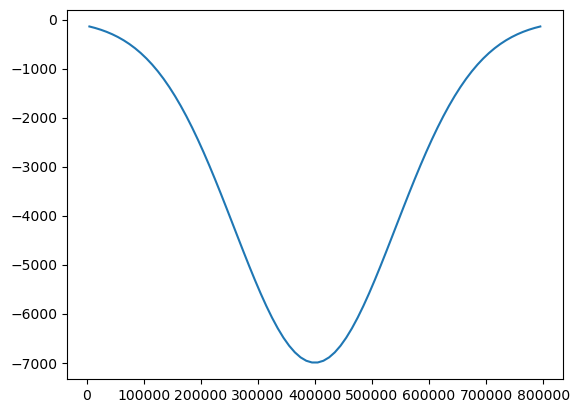

In [4]:
model_z = -7000 * gaussian(model_x, 400e3, 200e3)
plt.plot(model_x, model_z)

In [5]:
ymin, ymax = -1000e3, 1000e3  # m
prisms = np.empty((model_x.size, 6))
prisms[:, 0] = model_x - deltax / 2
prisms[:, 1] = model_x + deltax / 2
prisms[:, 2] = ymin
prisms[:, 3] = ymax
prisms[:, 4] = model_z
prisms[:, 5] = 0
density = np.full_like(model_x, -200)

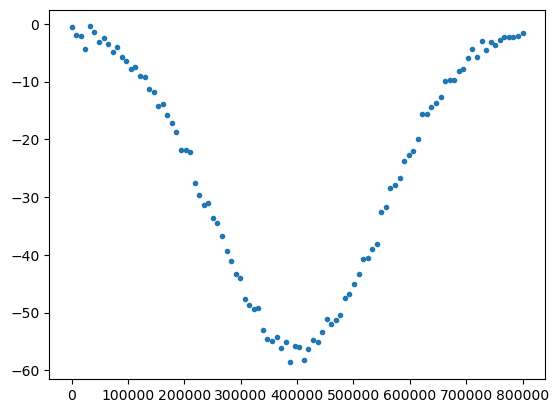

In [6]:
x = bd.line_coordinates(xmin, xmax, size=100)
coordinates = (x, np.zeros_like(x), np.full_like(x, 500))
data = hm.prism_gravity(coordinates, prisms, density, field="g_z")
data += np.random.default_rng(2).normal(0, 1, data.size)
plt.plot(x, data, ".")

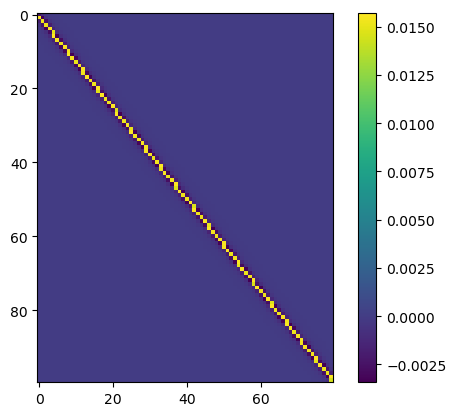

In [7]:
p0 = np.full_like(model_x, -2000)
G = np.empty((data.size, p0.size))
for j in range(p0.size):
    result = 0
    for i, y in enumerate([ymin, ymax]):
        for k, x in enumerate([model_x[j] - deltax / 2, model_x[j] + deltax / 2]):
            x = x - coordinates[0]
            y = y - coordinates[1]
            z2 = p0[j] - coordinates[2]
            r = np.sqrt(x**2 + y**2 + z2**2)
            result += (-1)**(i + k) * (
                -1e5  # m/s² to mGal
                * hm.constants.GRAVITATIONAL_CONST
                * density[j]
                * (
                    x * z2 / ((y + r) * r)
                    + y * z2 / ((x + r) * r)
                    + np.arctan2(x * y, z2 * r)
                    - z2 * x * y
                    * (
                        1 / (1 + (x * y / (z2 * r))**2)
                        * (
                            1 / (z2**2 * r)
                            + 1 / r**3
                        )
                    )
                )
            )        
    G[:, j] = result

plt.imshow(G)
plt.colorbar()

In [8]:
p0 = np.full_like(model_x, -2000)
p = p0.copy()
for iteration in range(10):
    G = np.empty((data.size, p.size))
    for j in range(p.size):
        result = 0
        for i, y in enumerate([ymin, ymax]):
            for k, x in enumerate([model_x[j] - deltax / 2, model_x[j] + deltax / 2]):
                x = x - coordinates[0]
                y = y - coordinates[1]
                z2 = p[j] - coordinates[2]
                r = np.sqrt(x**2 + y**2 + z2**2)
                result += (-1)**(i + k) * (
                    -1e5  # m/s² to mGal
                    * hm.constants.GRAVITATIONAL_CONST
                    * density[j]
                    * (
                        x * z2 / ((y + r) * r)
                        + y * z2 / ((x + r) * r)
                        + np.arctan2(x * y, z2 * r)
                        - z2 * x * y
                        * (
                            1 / (1 + (x * y / (z2 * r))**2)
                            * (
                                1 / (z2**2 * r)
                                + 1 / r**3
                            )
                        )
                    )
                )        
        G[:, j] = result    
    prisms = np.empty((p.size, 6))
    prisms[:, 0] = model_x - deltax / 2
    prisms[:, 1] = model_x + deltax / 2
    prisms[:, 2] = ymin
    prisms[:, 3] = ymax
    prisms[:, 4] = p
    prisms[:, 5] = 0
    predicted = hm.prism_gravity(coordinates, prisms, density, field="g_z") 
    deltap = np.linalg.solve(G.T @ G, G.T @ (data - predicted))
    p += deltap    

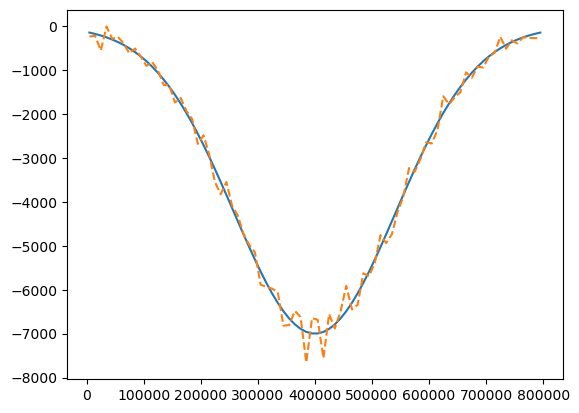

In [9]:
plt.plot(model_x, model_z)
plt.plot(model_x, p, "--")